# Lesson 1 — Homework

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/djnzx/ida-practice-3d/blob/main/practice/1/1-homework.ipynb)

**Estimated time: 3-4 hours.**

## How to work through this

Each task gives you a function signature and a docstring stating exactly
what the function must return. Replace the `raise NotImplementedError` with
your implementation. The cell immediately after each task contains
`assert` statements that check your work.

**A failing assert is information, not a grade.** It tells you that the
behaviour does not yet match the contract. Read the assertion message, fix
the function, re-run the cell. There is no penalty for running a cell
twenty times.

The written questions are marked. They are the part of this homework that
carries the learning objective: each one asks you to *run something both
ways and explain the difference*, not to recall a fact. Answers of one
sentence will not be enough; answers of one paragraph, referring to numbers
you actually produced, will.

Every function you need has been demonstrated in `1-practice.ipynb`. Each
task names the section — `see Practice 1 §3.6` — where the relevant material
is. You should not need any other documentation, and you should not need to
search the internet. If you find yourself wanting to, the reference is
probably in the practice notebook and worth finding.

## Before you submit

**Runtime → Restart and run all must complete without error**, with every
assert passing. A notebook that only works because you ran the cells in an
unusual order is not reproducible, and reproducibility is the subject of
§4.1 of the practice notebook.

Then **File → Download → Download .ipynb**, rename the file to
`1-homework-results.ipynb`, and commit it to your fork under
`practice/1/`. Keep the outputs in the file; do not clear them.
The full procedure is in `practice/README.md` §8.

## 1. Setup

Run this first. It is the same configuration cell as the practice notebook.

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt

SEED = 20250919
rng = np.random.default_rng(SEED)

plt.rcParams["figure.figsize"] = (7.0, 4.5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["font.size"] = 11
plt.rcParams["lines.linewidth"] = 2.0

print("python", sys.version.split()[0], "| numpy", np.__version__)

python 3.12.3 | numpy 2.0.2


## 2. Task 1 — Describe an array

Mechanical. Return the five attributes that describe an array's layout.

*see Practice 1 §3.2*

In [2]:
def describe_array(arr):
    """Return a dict describing the memory layout of `arr`.

    Keys, exactly these five:
        'dtype'    the element type, as a string (use str(...) on the dtype)
        'shape'    the shape, as a tuple
        'ndim'     the number of dimensions, as an int
        'size'     the total number of elements, as an int
        'nbytes'   the total number of bytes occupied by the data, as an int

    No allocation and no copying: read the attributes off `arr`.
    """
    return {
        "dtype": str(arr.dtype),
        "shape": tuple(arr.shape),
        "ndim": int(arr.ndim),
        "size": int(arr.size),
        "nbytes": int(arr.nbytes),
    }

In [3]:
_result = describe_array(np.zeros((3, 4), dtype=np.float64))
assert set(_result) == {"dtype", "shape", "ndim", "size", "nbytes"}, \
    f"expected exactly those five keys, got {sorted(_result)}"
assert _result["shape"] == (3, 4), f"shape wrong: {_result['shape']}"
assert _result["ndim"] == 2, f"ndim wrong: {_result['ndim']}"
assert _result["size"] == 12, f"size wrong: {_result['size']}"
assert _result["nbytes"] == 96, f"nbytes wrong: {_result['nbytes']} (12 elements x 8 bytes)"
assert "float64" in _result["dtype"], f"dtype wrong: {_result['dtype']}"

_int_result = describe_array(np.arange(10, dtype=np.int32))
assert _int_result["nbytes"] == 40, "an int32 array of 10 elements occupies 40 bytes"
assert _int_result["ndim"] == 1

print("Task 1 passed.")

Task 1 passed.


## 3. Task 2 — A view bug, and the fix

The function below is supposed to return a copy of the middle of an array
with its values clipped to zero, leaving the caller's array untouched. It
does not. Find the defect and repair it.

Do not change the signature and do not change what the function returns —
only make it stop modifying its argument.

*see Practice 1 §3.6*

In [4]:
def zero_the_middle(arr, start, stop):
    """Return a NEW array holding arr[start:stop] with every value set to 0.

    `arr` must not be modified. The returned array must have length
    stop - start and must not share memory with `arr`.

    The body below is the broken version. Fix it.
    """
    # A basic slice is a view on the same buffer (Practice 1 §3.6), so writing
    # into it wrote into the caller's array. .copy() gives the slice its own memory.
    middle = arr[start:stop].copy()
    middle[:] = 0
    return middle

In [5]:
_original = np.arange(10)
_untouched = np.arange(10)
_returned = zero_the_middle(_original, 3, 6)

assert np.array_equal(_original, _untouched), \
    f"the argument was modified: {_original} should still be {_untouched}"
assert _returned.shape == (3,), f"wrong length: {_returned.shape}"
assert np.all(_returned == 0), f"values not zeroed: {_returned}"
assert not np.shares_memory(_returned, _original), \
    "the result still shares memory with the argument"

print("Task 2 passed.")

Task 2 passed.


## 4. Task 3 — Standardise the columns of a matrix

Applied. Subtract each column's mean and divide by each column's standard
deviation, using broadcasting rather than a loop over columns.

This is what `StandardScaler` does, and Practice 2 §9 will use the
scikit-learn object. Writing it once by hand is the point.

*see Practice 1 §3.7 and §3.8*

In [6]:
def standardise_columns(matrix):
    """Return `matrix` with every column centred and scaled to unit variance.

    For each column j:  out[:, j] = (matrix[:, j] - mean_j) / sd_j

    Use the population standard deviation (NumPy's default, ddof=0).
    The result has the same shape as `matrix`. Do not modify `matrix`.
    Use broadcasting; do not write a `for` loop over the columns.
    """
    means = matrix.mean(axis=0)   # shape (n_columns,)
    sds = matrix.std(axis=0)      # shape (n_columns,), ddof=0
    # (n_rows, n_columns) - (n_columns,) broadcasts along the rows
    return (matrix - means) / sds

In [7]:
_data = np.array([[1.0, 100.0],
                  [2.0, 200.0],
                  [3.0, 300.0],
                  [4.0, 400.0]])
_before = _data.copy()
_scaled = standardise_columns(_data)

assert _scaled.shape == _data.shape, f"shape changed: {_scaled.shape}"
assert np.array_equal(_data, _before), "the input matrix was modified"
assert np.allclose(_scaled.mean(axis=0), 0.0), \
    f"columns not centred, means are {_scaled.mean(axis=0)}"
assert np.allclose(_scaled.std(axis=0), 1.0), \
    f"columns not unit variance, sds are {_scaled.std(axis=0)}"
# The two columns are the same numbers on different scales, so after
# standardising they must be identical.
assert np.allclose(_scaled[:, 0], _scaled[:, 1]), \
    "a linear rescaling of a column should standardise to the same values"

_wide = rng.normal(5.0, 3.0, size=(200, 7))
assert np.allclose(standardise_columns(_wide).mean(axis=0), 0.0, atol=1e-12)
assert np.allclose(standardise_columns(_wide).std(axis=0), 1.0)

print("Task 3 passed.")

Task 3 passed.


## 5. Task 4 — Reductions along an axis

Mechanical, but the axis argument is the thing being tested. Read the
docstring carefully: two of these collapse rows and two collapse columns.

*see Practice 1 §3.8*

In [8]:
def axis_summary(matrix):
    """Return a dict of four reductions of a 2-D array.

    Keys and contents:
        'per_column_mean'  one value per COLUMN, shape (n_columns,)
        'per_row_sum'      one value per ROW,    shape (n_rows,)
        'per_row_max'      one value per ROW,    shape (n_rows,)
        'grand_total'      the sum of every element, a scalar float

    Return NumPy arrays for the first three and a Python/NumPy float for
    the last.
    """
    return {
        "per_column_mean": matrix.mean(axis=0),   # collapse the rows
        "per_row_sum": matrix.sum(axis=1),        # collapse the columns
        "per_row_max": matrix.max(axis=1),
        "grand_total": float(matrix.sum()),
    }

In [9]:
_grid = np.array([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])
_summary = axis_summary(_grid)

assert _summary["per_column_mean"].shape == (3,), \
    f"per_column_mean should have one value per column: {_summary['per_column_mean'].shape}"
assert np.allclose(_summary["per_column_mean"], [2.5, 3.5, 4.5])
assert _summary["per_row_sum"].shape == (2,), \
    f"per_row_sum should have one value per row: {_summary['per_row_sum'].shape}"
assert np.allclose(_summary["per_row_sum"], [6.0, 15.0])
assert np.allclose(_summary["per_row_max"], [3.0, 6.0])
assert np.isclose(_summary["grand_total"], 21.0)

# A non-square array catches an axis swapped by accident.
_tall = rng.normal(size=(50, 4))
_tall_summary = axis_summary(_tall)
assert _tall_summary["per_column_mean"].shape == (4,)
assert _tall_summary["per_row_sum"].shape == (50,)

print("Task 4 passed.")

Task 4 passed.


### Question 1 — the axis argument

Take the `(50, 4)` array `_tall` from the cell above. Compute `_tall.sum()`,
`_tall.sum(axis=0)` and `_tall.sum(axis=1)`, and print the shape of each.

Explain, in your own words, **why `axis=0` produces four numbers and not
fifty**, given that the array has fifty rows. Then state which of the three
you would use to answer the question "what is the average value of each
feature across all samples", and why.

In [10]:
print("_tall.shape            :", _tall.shape)
print()
_total = _tall.sum()
_by_col = _tall.sum(axis=0)
_by_row = _tall.sum(axis=1)
print("_tall.sum()        shape", np.shape(_total), "  value", round(float(_total), 4))
print("_tall.sum(axis=0)  shape", _by_col.shape, "  values", _by_col.round(4))
print("_tall.sum(axis=1)  shape", _by_row.shape, "  first five", _by_row[:5].round(4))
print()
print("average of each feature over all samples, _tall.mean(axis=0):", _tall.mean(axis=0).round(4))
print("the same thing by hand, sum(axis=0) / n_rows                 :",
      (_by_col / _tall.shape[0]).round(4))

_tall.shape            : (50, 4)

_tall.sum()        shape ()   value -9.7922
_tall.sum(axis=0)  shape (4,)   values [-8.0218 -0.81    8.2115 -9.1719]
_tall.sum(axis=1)  shape (50,)   first five [-0.5051 -2.0902  0.158   0.2296 -0.4013]

average of each feature over all samples, _tall.mean(axis=0): [-0.1604 -0.0162  0.1642 -0.1834]
the same thing by hand, sum(axis=0) / n_rows                 : [-0.1604 -0.0162  0.1642 -0.1834]


**Your answer:**

Масив `_tall` має форму `(50, 4)`: 50 рядків (зразків) і 4 стовпці (ознаки). Виклик `_tall.sum()` без аргументу згортає обидві осі й повертає скаляр із формою `()`, у моєму запуску це −9,7922. `_tall.sum(axis=0)` дає форму `(4,)`, а `_tall.sum(axis=1)` дає форму `(50,)`.

Причина в тому, що `axis` називає вісь, яку редукція **знищує**, а не ту, що залишається. Вісь 0 нумерує рядки, тому `axis=0` складає між собою всі 50 рядків: для кожного стовпця підсумовуються 50 значень, вісь довжини 50 зникає, а вісь довжини 4 зберігається. Звідси чотири числа (−8,0218; −0,8100; 8,2115; −9,1719), по одному на стовпець. `axis=1`, навпаки, знищує вісь стовпців і дає 50 сум, по одній на рядок.

Для запитання «яке середнє значення кожної ознаки по всіх зразках» потрібна `axis=0`, тобто `_tall.mean(axis=0)`, бо ознаки розміщені в стовпцях, а усереднювати треба по зразках, тобто вздовж рядків. Отримано [−0,1604; −0,0162; 0,1642; −0,1834], і ці значення точно збігаються з `sum(axis=0) / 50`. Варіант `axis=1` відповідав би на інше запитання (середнє всіх ознак одного зразка, яке має сенс лише для однорідних величин), а `sum()` без осі змішав би всі ознаки в одне число. Те, що середні близькі до нуля, очікувано, адже `_tall` згенеровано зі стандартного нормального розподілу і кожне середнє обчислено лише з 50 значень.

## 6. Task 5 — Outliers by the k-sigma rule

Applied. Generalise the practice notebook's 3σ filter to an arbitrary threshold.

*see Practice 1 §3.9 and §4.7*

In [11]:
def sigma_outliers(sample, k=3.0):
    """Flag the values of `sample` that lie more than k standard deviations
    from the sample mean.

    Use the mean and standard deviation OF THE SAMPLE itself, not assumed
    values, and NumPy's default ddof=0 for the standard deviation.

    Return a tuple (mask, values):
        mask    a boolean array, the same shape as `sample`, True where the
                value is an outlier
        values  the outlying values themselves, in their original order

    Build the mask with a vectorised comparison; do not loop.
    """
    centre = sample.mean()
    spread = sample.std()          # ddof=0
    mask = np.abs(sample - centre) > k * spread
    return mask, sample[mask]

In [12]:
_plain = np.array([1.0, 2.0, 3.0, 2.0, 1.0, 50.0])
_mask, _values = sigma_outliers(_plain, k=2.0)

assert _mask.dtype == bool, f"mask must be boolean, got {_mask.dtype}"
assert _mask.shape == _plain.shape, f"mask shape {_mask.shape} != sample shape {_plain.shape}"
assert _mask.sum() == 1, f"expected exactly one outlier at k=2, found {_mask.sum()}"
assert np.allclose(_values, [50.0]), f"wrong value flagged: {_values}"

# On a clean normal sample the 3-sigma rule should flag very few points.
_normal = rng.normal(0.0, 1.0, 10_000)
_normal_mask, _ = sigma_outliers(_normal, k=3.0)
_rate = _normal_mask.mean()
assert 0.0 < _rate < 0.01, \
    f"flag rate {_rate:.4f} is implausible for 3 sigma on normal data (expect ~0.0027)"

# A larger threshold can never flag more points than a smaller one.
assert sigma_outliers(_normal, k=4.0)[0].sum() <= _normal_mask.sum()

print(f"Task 5 passed. 3-sigma flag rate on 10,000 normal draws: {_rate:.4%}")

Task 5 passed. 3-sigma flag rate on 10,000 normal draws: 0.3100%


### Question 2 — the threshold is a choice

Using the 10 000-point normal sample `_normal`, run `sigma_outliers` at
`k = 1, 2, 3, 4, 5` and print the number of points flagged at each.

Then answer: the theoretical fractions outside k standard deviations of a
normal distribution are about 32 %, 4.6 %, 0.27 %, 0.0063 % and 0.000057 %.
Compare your counts with those. **At which k does the sample stop having
enough data to estimate the rate at all**, and what does that imply about
using a very large k to define an outlier?

Finally: none of the points in `_normal` is an error — they all came from
the same generator. Describe one concrete situation in which you *would* be
justified in deleting a flagged point, and say what evidence would justify
it.

In [13]:
import math

print(f"sample mean {_normal.mean():+.4f}, sample sd {_normal.std():.4f}, n = {_normal.size}")
print()
print(f"{'k':>2} {'flagged':>8} {'observed %':>11} {'theory %':>11} {'expected count':>15}")
for _k in (1, 2, 3, 4, 5):
    _flagged = int(sigma_outliers(_normal, k=_k)[0].sum())
    _p_theory = math.erfc(_k / math.sqrt(2))          # two-sided tail of N(0, 1)
    print(f"{_k:>2} {_flagged:>8} {100 * _flagged / _normal.size:>10.4f}% "
          f"{100 * _p_theory:>10.6f}% {_normal.size * _p_theory:>15.4f}")

# How many draws would one need to expect even ten points beyond k sigma?
print()
for _k in (3, 4, 5):
    print(f"to expect 10 points beyond {_k} sigma you need about "
          f"{10 / math.erfc(_k / math.sqrt(2)):,.0f} draws")

sample mean -0.0117, sample sd 1.0101, n = 10000

 k  flagged  observed %    theory %  expected count
 1     3163    31.6300%  31.731051%       3173.1051
 2      454     4.5400%   4.550026%        455.0026
 3       31     0.3100%   0.269980%         26.9980
 4        2     0.0200%   0.006334%          0.6334
 5        0     0.0000%   0.000057%          0.0057

to expect 10 points beyond 3 sigma you need about 3,704 draws
to expect 10 points beyond 4 sigma you need about 157,872 draws
to expect 10 points beyond 5 sigma you need about 17,442,779 draws


**Your answer:**

Отримані кількості позначених точок для 10 000 нормальних значень такі: при k = 1 позначено 3163 (31,63 %; теорія 31,73 %, тобто 3173 точки), при k = 2 позначено 454 (4,54 % проти 4,55 %, 455 точок), при k = 3 позначено 31 (0,31 % проти 0,27 %, 27 точок), при k = 4 позначено 2 (0,02 % проти 0,0063 %, 0,63 точки), при k = 5 не позначено жодної (теорія 0,0057 точки). Для k = 1 і k = 2 збіг з теорією дуже добрий, для k = 3 розбіжність у 4 точки ще цілком у межах випадкового коливання.

Вибірка перестає дозволяти оцінити частку вже при **k = 4**. Очікувана кількість точок за межею менша за одну (0,63), тому і 0, і 1, і 2 спостереження однаково сумісні з теорією. Формально спостережена частка 0,02 % втричі більша за теоретичну, але дві точки нічого не доводять. При k = 5 потрібно близько 17,4 млн значень, щоб очікувати хоча б десять точок за межею, а при k = 4 близько 158 тис. Отже, дуже великий k визначає викид через подію, частоту якої дані не здатні виміряти. Такий поріг фактично є припущенням про форму хвостів (що вони точно нормальні), а перевірити це припущення на тій самій вибірці неможливо. Якщо реальні хвости важчі за нормальні, за межею великого k опиниться в рази більше точок, ніж обіцяє теорія, а якщо вибірка мала, правило не спрацює взагалі, навіть коли справжні помилки в даних є. До того ж середнє і стандартне відхилення тут оцінюються з тієї ж вибірки, тож поріг сам є випадковою величиною.

Жодна точка в `_normal` не є помилкою, тому видаляти їх не можна. Виправдана ситуація інша: наприклад, у таблиці температур тіла пацієнтів у °C трапляється значення 98,6. Воно далеко за 3σ, але причина не в статистиці, а в тому, що його записано у Фаренгейтах (98,6 °F = 37 °C). Обґрунтуванням видалення (або виправлення) тут є незалежний від правила факт про процес вимірювання: фізична неможливість значення в заявлених одиницях, запис у журналі приладу про збій або код помилки на цю мить, повторне вимірювання того самого об'єкта з нормальним результатом, розбіжність з первинним документом. Правило k-сигм лише вказує, куди дивитися, а рішення має спиратися на такий доказ.

## 7. Task 6 — A NaN-aware mean, written by hand

Mechanical. Do not call `np.nanmean`; the point is to build it from the
masking tools.

*see Practice 1 §3.9 and §3.10*

In [14]:
def mean_ignoring_nan(sample):
    """Return the mean of the non-missing values of `sample`.

    Equivalent to np.nanmean, but you must implement it with np.isnan and
    boolean masking rather than calling any nan-aware NumPy reduction.

    If every value is missing, return np.nan.
    """
    present = ~np.isnan(sample)
    n_present = present.sum()
    if n_present == 0:
        return np.nan
    return sample[present].sum() / n_present

In [15]:
assert np.isclose(mean_ignoring_nan(np.array([1.0, 2.0, np.nan, 4.0])), 7.0 / 3.0)
assert np.isclose(mean_ignoring_nan(np.array([5.0, 5.0, 5.0])), 5.0)
assert np.isnan(mean_ignoring_nan(np.array([np.nan, np.nan]))), \
    "an all-missing sample has no mean; return np.nan"

_with_gaps = rng.normal(0.0, 1.0, 1000)
_with_gaps[rng.choice(1000, size=100, replace=False)] = np.nan
assert np.isclose(mean_ignoring_nan(_with_gaps), np.nanmean(_with_gaps)), \
    "your result should agree with np.nanmean"
assert np.isnan(_with_gaps.mean()), \
    "sanity check: the plain mean of an array containing NaN is NaN"

print("Task 6 passed.")

Task 6 passed.


## 8. Task 7 — How well does a sample know its own distribution

Applied. Draw samples of increasing size from a known normal distribution
and measure how far the estimated parameters fall from the true ones.

*see Practice 1 §4.1 and §4.6*

In [16]:
def recover_parameters(true_mu, true_sigma, sizes, generator):
    """Estimate mu and sigma from samples of several sizes.

    For each n in `sizes`, draw n values from normal(true_mu, true_sigma)
    using `generator`, and record the sample mean and the UNBIASED sample
    standard deviation (ddof=1).

    Draw the samples in the order the sizes are given, taking every sample
    from the same `generator` object, so that the result is reproducible
    for a given seed.

    Return a dict with three keys, each a NumPy array of len(sizes):
        'n'          the sample sizes, as given
        'mu_hat'     the estimated means
        'sigma_hat'  the estimated standard deviations
    """
    mu_hat, sigma_hat = [], []
    for n in sizes:
        sample = generator.normal(true_mu, true_sigma, n)
        mu_hat.append(sample.mean())
        sigma_hat.append(sample.std(ddof=1))
    return {
        "n": np.array(sizes),
        "mu_hat": np.array(mu_hat),
        "sigma_hat": np.array(sigma_hat),
    }

In [17]:
_sizes = [10, 100, 1_000, 10_000, 100_000]
_recovered = recover_parameters(2.0, 5.0, _sizes, np.random.default_rng(0))

assert set(_recovered) == {"n", "mu_hat", "sigma_hat"}
assert len(_recovered["mu_hat"]) == len(_sizes)
assert np.array_equal(_recovered["n"], np.array(_sizes))

# Reproducible: the same seed must give the same estimates.
_again = recover_parameters(2.0, 5.0, _sizes, np.random.default_rng(0))
assert np.allclose(_recovered["mu_hat"], _again["mu_hat"]), \
    "same seed gave different answers; are you drawing from the generator you were passed?"

# The largest sample must land close to the truth.
assert abs(_recovered["mu_hat"][-1] - 2.0) < 0.1, \
    f"mu estimate from 100,000 draws is {_recovered['mu_hat'][-1]:.4f}, expected near 2.0"
assert abs(_recovered["sigma_hat"][-1] - 5.0) < 0.1, \
    f"sigma estimate from 100,000 draws is {_recovered['sigma_hat'][-1]:.4f}, expected near 5.0"

# and the error should shrink as n grows
_err_small = abs(_recovered["mu_hat"][0] - 2.0)
_err_large = abs(_recovered["mu_hat"][-1] - 2.0)
assert _err_large < _err_small, "the estimate should improve with more data"

for n, mu, sd in zip(_recovered["n"], _recovered["mu_hat"], _recovered["sigma_hat"]):
    print(f"n = {n:7,}   mu_hat = {mu:8.4f}   sigma_hat = {sd:8.4f}")
print("\nTask 7 passed.")

n =      10   mu_hat =   2.4234   sigma_hat =   3.9067
n =     100   mu_hat =   2.2577   sigma_hat =   4.9827
n =   1,000   mu_hat =   1.7686   sigma_hat =   4.9318
n =  10,000   mu_hat =   2.0434   sigma_hat =   5.0002
n = 100,000   mu_hat =   1.9896   sigma_hat =   5.0035

Task 7 passed.


### Question 3 — the seed and the sample size

Two experiments.

**(a)** Call `recover_parameters(2.0, 5.0, [100], ...)` with five *different*
seeds. Record the five estimates of mu. How much do they vary?

**(b)** Call it with a single fixed seed but sizes `[100, 10_000]`. How far
is each estimate from 2.0?

Now explain the distinction these two experiments draw out. **The seed
controls one thing and the sample size controls a different thing — name
both.** In particular: does a larger seed give a better answer? Does
re-running with a new seed tell you anything you did not know? And if your
estimate at n = 100 is off by 0.4, is that a bug?

Use the error at n = 100 and at n = 10 000 to estimate how the error scales
with n, and compare it with the square-root rule from Practice 1 §4.6.

In [18]:
# (a) the same n = 100, five different seeds
_seeds = [1, 2, 3, 4, 5]
_mu_by_seed = np.array([
    recover_parameters(2.0, 5.0, [100], np.random.default_rng(s))["mu_hat"][0] for s in _seeds
])
print("(a) n = 100, five seeds")
for s, m in zip(_seeds, _mu_by_seed):
    print(f"    seed {s}: mu_hat = {m:.4f}   error {m - 2.0:+.4f}")
print(f"    range {_mu_by_seed.max() - _mu_by_seed.min():.4f}, "
      f"sd across seeds {_mu_by_seed.std(ddof=1):.4f}")

# a "large" seed is not a better seed
_big = recover_parameters(2.0, 5.0, [100], np.random.default_rng(10**9))["mu_hat"][0]
print(f"    seed 1_000_000_000: mu_hat = {_big:.4f}   error {_big - 2.0:+.4f}")

# (b) one fixed seed, two sizes
_fixed = recover_parameters(2.0, 5.0, [100, 10_000], np.random.default_rng(0))
print("\n(b) seed 0, sizes [100, 10_000]")
for n, m in zip(_fixed["n"], _fixed["mu_hat"]):
    print(f"    n = {n:6,}: mu_hat = {m:.4f}   |error| {abs(m - 2.0):.4f}")

# The error from one seed is itself one random draw. Repeat over 500 seeds
# to see how the typical error depends on n.
_rms = {}
for n in (100, 10_000):
    _errs = np.array([
        recover_parameters(2.0, 5.0, [n], np.random.default_rng(s))["mu_hat"][0] - 2.0
        for s in range(500)
    ])
    _rms[n] = np.sqrt(np.mean(_errs ** 2))
    print(f"\n    over 500 seeds, n = {n:6,}: RMS error {_rms[n]:.4f}   "
          f"theory sigma/sqrt(n) = {5.0 / np.sqrt(n):.4f}   "
          f"share of runs off by more than 0.4: {np.mean(np.abs(_errs) > 0.4):.3f}")
print(f"\n    ratio of RMS errors {_rms[100] / _rms[10_000]:.2f} for a 100x increase in n "
      f"(square-root rule predicts {np.sqrt(100):.0f})")

(a) n = 100, five seeds
    seed 1: mu_hat = 1.6319   error -0.3681
    seed 2: mu_hat = 1.9579   error -0.0421
    seed 3: mu_hat = 1.6911   error -0.3089
    seed 4: mu_hat = 1.6835   error -0.3165
    seed 5: mu_hat = 0.8800   error -1.1200
    range 1.0779, sd across seeds 0.4056
    seed 1_000_000_000: mu_hat = 2.3071   error +0.3071

(b) seed 0, sizes [100, 10_000]
    n =    100: mu_hat = 2.4055   |error| 0.4055
    n = 10,000: mu_hat = 2.0219   |error| 0.0219

    over 500 seeds, n =    100: RMS error 0.5256   theory sigma/sqrt(n) = 0.5000   share of runs off by more than 0.4: 0.430



    over 500 seeds, n = 10,000: RMS error 0.0496   theory sigma/sqrt(n) = 0.0500   share of runs off by more than 0.4: 0.000

    ratio of RMS errors 10.60 for a 100x increase in n (square-root rule predicts 10)


**Your answer:**

**(a)** При n = 100 п'ять різних seed дали оцінки μ: 1,6319; 1,9579; 1,6911; 1,6835; 0,8800. Похибки коливаються від −0,04 до −1,12, розмах становить 1,08, а стандартне відхилення оцінок між seed дорівнює 0,41. Це близько до теоретичної стандартної похибки середнього σ/√n = 5/√100 = 0,5. Те, що всі п'ять оцінок нижчі за 2,0, є збігом: для seed 10⁹ отримано 2,3071 (похибка +0,31), а для seed 0 у пункті (b) 2,4055.

**(b)** З одним seed = 0 і розмірами [100, 10 000] оцінки дорівнюють 2,4055 (похибка 0,4055) і 2,0219 (похибка 0,0219).

Seed керує тим, **яку саме** вибірку буде витягнуто, тобто конкретною реалізацією випадковості, і цим забезпечує відтворюваність: той самий seed дає ті самі числа. Розмір вибірки керує **точністю**, тобто тим, наскільки сильно оцінка коливається від вибірки до вибірки. Більший seed не дає кращої відповіді: число 10⁹ не «якісніше» за 1, воно просто вибирає іншу вибірку, і похибка 0,31 для нього цілком типова. Повторний запуск з новим seed нічого не говорить про справжнє μ понад те, що вже дав перший запуск, бо це ще одне значення з того самого розподілу оцінок. Корисним він стає лише тоді, коли повторів багато і нас цікавить розкид оцінки, як у моїх 500 повторах. Похибка 0,4 при n = 100 не є помилкою в коді: вона менша за одну стандартну похибку 0,5, і серед 500 seed частка запусків з |похибкою| > 0,4 дорівнює 0,43.

Похибки одного запуску (0,4055 і 0,0219) відрізняються у 18,5 раза, але кожна з них сама випадкова, тому для оцінки масштабування я взяв середньоквадратичну похибку за 500 seed: 0,5256 при n = 100 і 0,0496 при n = 10 000 (теорія 0,5 і 0,05). Відношення 10,60 при стократному збільшенні обсягу добре узгоджується з правилом квадратного кореня з Practice 1 §4.6, яке передбачає √100 = 10. Отже, у сто разів більше даних дає приблизно вдесятеро точнішу оцінку.

## 9. Task 8 — Build a correlated cloud

Applied. Construct a 2-D Gaussian sample with a specified correlation, and
confirm you got what you asked for.

*see Practice 1 §4.9*

In [19]:
def correlated_cloud(sd_x, sd_y, correlation, n, generator):
    """Draw `n` points from a 2-D normal centred at the origin with the given
    marginal standard deviations and correlation.

    Build the covariance matrix yourself from the three parameters:

        [[ sd_x**2,                      correlation*sd_x*sd_y ],
         [ correlation*sd_x*sd_y,        sd_y**2               ]]

    Draw from it with generator.multivariate_normal.

    Return a tuple (points, covariance):
        points      shape (n, 2)
        covariance  the 2x2 matrix you built, shape (2, 2)
    """
    off_diagonal = correlation * sd_x * sd_y
    covariance = np.array([[sd_x ** 2, off_diagonal],
                           [off_diagonal, sd_y ** 2]])
    points = generator.multivariate_normal(np.zeros(2), covariance, size=n)
    return points, covariance

In [20]:
_points, _cov = correlated_cloud(3.0, 3.0, 0.8, 20_000, np.random.default_rng(1))

assert _points.shape == (20_000, 2), f"wrong shape: {_points.shape}"
assert _cov.shape == (2, 2)
assert np.isclose(_cov[0, 0], 9.0), f"variance of x should be sd_x**2 = 9, got {_cov[0, 0]}"
assert np.isclose(_cov[0, 1], _cov[1, 0]), "a covariance matrix is symmetric"
assert np.isclose(_cov[0, 1], 7.2), f"off-diagonal should be 0.8*3*3 = 7.2, got {_cov[0, 1]}"

_measured = np.corrcoef(_points.T)[0, 1]
assert abs(_measured - 0.8) < 0.02, \
    f"the sample correlation is {_measured:.4f}, expected close to 0.8"

# a zero correlation must give an axis-aligned cloud
_indep, _ = correlated_cloud(2.0, 5.0, 0.0, 20_000, np.random.default_rng(2))
assert abs(np.corrcoef(_indep.T)[0, 1]) < 0.03

print(f"Task 8 passed. Measured correlation {_measured:.4f} against a requested 0.8.")

Task 8 passed. Measured correlation 0.7963 against a requested 0.8.


## 10. Task 9 — A figure that can be read without its caption

Applied. Draw the two clouds side by side, correctly labelled.

Requirements, all of which the assert checks:

- one `Figure` with two `Axes`, side by side
- left panel: correlation 0.0; right panel: correlation 0.9
- both panels: an x label, a y label, a title, and equal aspect
- a title on the figure as a whole

*see Practice 1 §4.9 and §5*

In [21]:
def compare_correlations(generator):
    """Draw two 2-D clouds side by side and return (fig, axes).

    Both clouds: sd_x = sd_y = 2.0, n = 2000, drawn with `generator`
    via correlated_cloud from Task 8.
    Left panel  correlation 0.0.
    Right panel correlation 0.9.

    Each Axes must have set_xlabel, set_ylabel, set_title and an equal
    aspect ratio. The Figure must have a suptitle.

    Return the Figure and the array of two Axes.
    """
    fig, axes = plt.subplots(1, 2, figsize=(11, 5.4), sharex=True, sharey=True,
                             layout="constrained")
    for ax, rho in zip(axes, (0.0, 0.9)):
        points, _ = correlated_cloud(2.0, 2.0, rho, 2000, generator)
        measured = np.corrcoef(points.T)[0, 1]
        ax.scatter(points[:, 0], points[:, 1], s=6, alpha=0.35)
        ax.set_xlabel("x  (sd 2.0)")
        ax.set_ylabel("y  (sd 2.0)")
        ax.set_title(f"correlation {rho:.1f} (measured {measured:.3f})")
        ax.set_aspect("equal")
    fig.suptitle("Two clouds with sd_x = sd_y = 2.0, n = 2000 each")
    return fig, axes

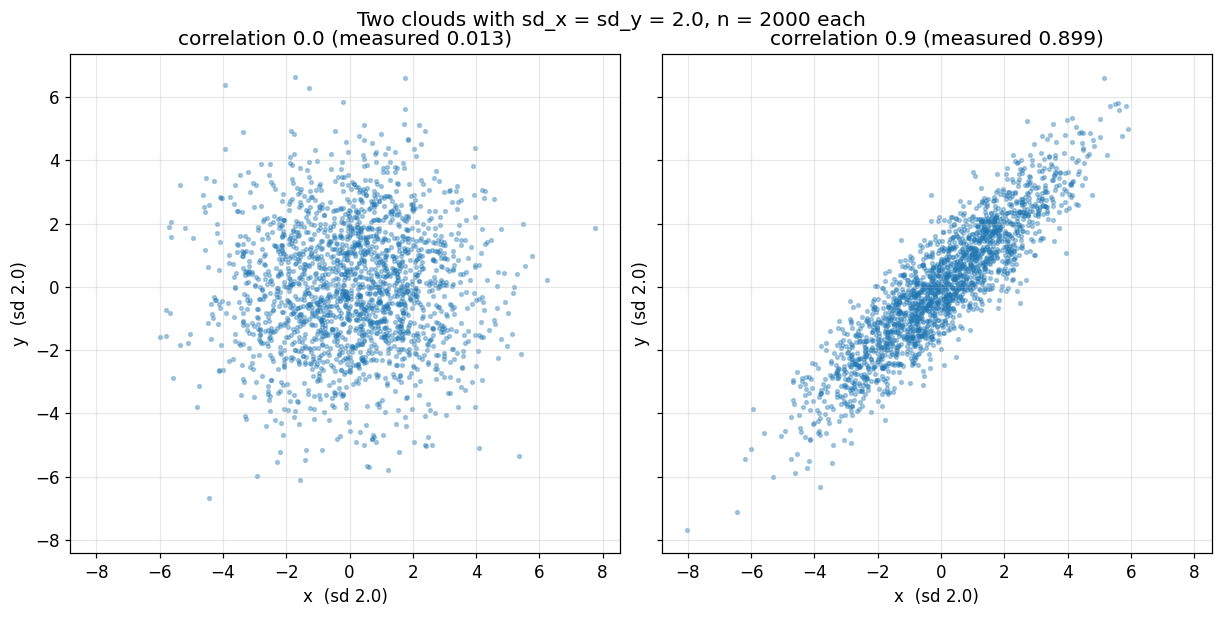

Task 9 passed.


In [22]:
_fig, _axes = compare_correlations(np.random.default_rng(3))

assert len(_axes) == 2, f"expected two Axes, got {len(_axes)}"
for _i, _ax in enumerate(_axes):
    assert _ax.get_xlabel(), f"panel {_i} has no x label"
    assert _ax.get_ylabel(), f"panel {_i} has no y label"
    assert _ax.get_title(), f"panel {_i} has no title"
    assert _ax.get_aspect() == 1.0, f"panel {_i} does not have equal aspect"
    assert len(_ax.collections) > 0, f"panel {_i} has nothing plotted on it"
assert _fig._suptitle is not None and _fig._suptitle.get_text(), \
    "the figure has no suptitle"

plt.show()
print("Task 9 passed.")

### Question 4 — the off-diagonal entry

Re-run `compare_correlations` mentally, or actually, with the right-hand
correlation set to **-0.9** instead of `0.9`.

Describe what changes in the picture and what does **not**. Specifically:
does the spread of `x` alone change? Does the spread of `y` alone change?
What would you see if you plotted a histogram of just the `x` coordinate
for correlation `0.0`, `0.9` and `-0.9` — could you tell the three cases
apart from that histogram?

Then state the consequence in one sentence: what does this say about
inspecting variables one at a time?

correlation   sd(x)   sd(y)  measured r
        0.0  2.0139  1.9912      0.0134
        0.9  1.9984  2.0066      0.8989
       -0.9  1.9597  1.9924     -0.8946


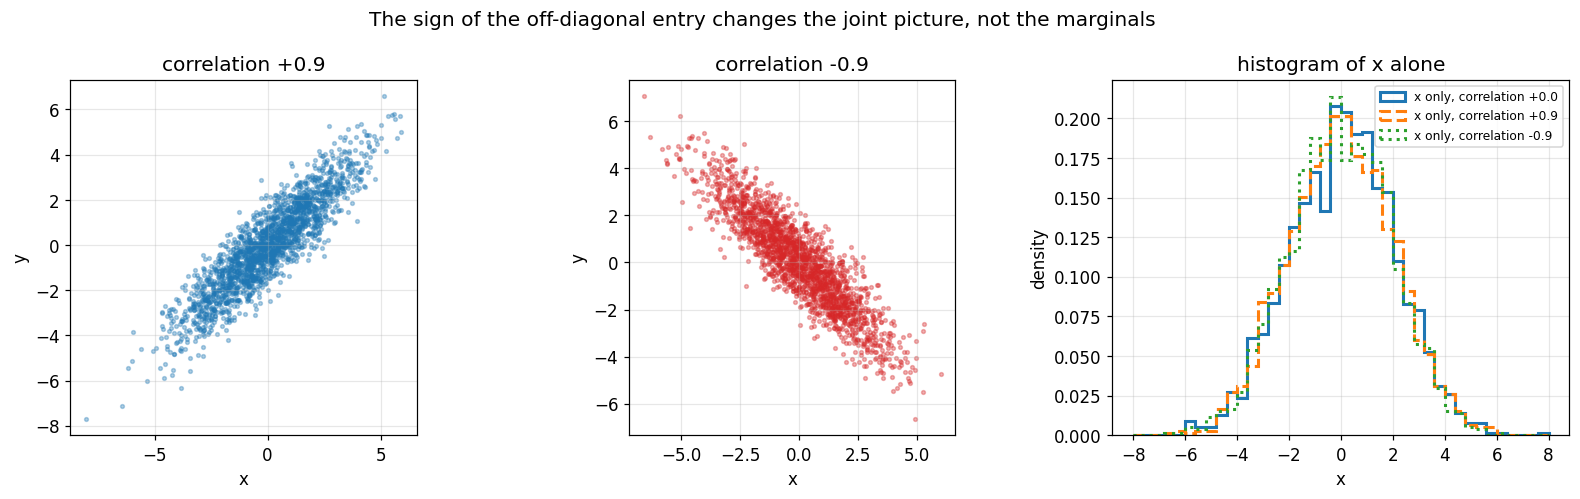

In [23]:
_q4_gen = np.random.default_rng(3)
_clouds = {rho: correlated_cloud(2.0, 2.0, rho, 2000, _q4_gen)[0] for rho in (0.0, 0.9, -0.9)}

print(f"{'correlation':>11} {'sd(x)':>7} {'sd(y)':>7} {'measured r':>11}")
for rho, pts in _clouds.items():
    print(f"{rho:>11.1f} {pts[:, 0].std():>7.4f} {pts[:, 1].std():>7.4f} "
          f"{np.corrcoef(pts.T)[0, 1]:>11.4f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for rho, colour in zip((0.9, -0.9), ("tab:blue", "tab:red")):
    axes[0 if rho > 0 else 1].scatter(_clouds[rho][:, 0], _clouds[rho][:, 1],
                                      s=6, alpha=0.35, color=colour)
for ax, rho in zip(axes[:2], (0.9, -0.9)):
    ax.set_title(f"correlation {rho:+.1f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
_edges = np.linspace(-8, 8, 41)
for rho, style in zip((0.0, 0.9, -0.9), ("-", "--", ":")):
    axes[2].hist(_clouds[rho][:, 0], bins=_edges, density=True, histtype="step",
                 linestyle=style, linewidth=2, label=f"x only, correlation {rho:+.1f}")
axes[2].set_title("histogram of x alone")
axes[2].set_xlabel("x")
axes[2].set_ylabel("density")
axes[2].legend(fontsize=8)
fig.suptitle("The sign of the off-diagonal entry changes the joint picture, not the marginals")
fig.tight_layout()
plt.show()

**Your answer:**

Я побудував три хмари з однаковими sd_x = sd_y = 2,0 і кореляцією 0,0, +0,9 та −0,9 (n = 2000). При −0,9 картина віддзеркалюється: хмара так само витягнута в еліпс, але вздовж прямої y = −x, тобто великі x супроводжуються малими y. Виміряна кореляція −0,8946 проти +0,8989 для +0,9 і 0,0134 для 0,0.

Розкид кожної координати окремо не змінюється. Стандартне відхилення x становить 2,0139, 1,9984 і 1,9597 для трьох випадків, y відповідно 1,9912, 2,0066 і 1,9924, тобто всі близькі до заданих 2,0, а відмінності в третьому знаку є шумом вибірки. Так і має бути, бо діагональ коваріаційної матриці (sd_x² = sd_y² = 4) в усіх трьох випадках однакова, а змінюється лише позадіагональний елемент (0; +3,6; −3,6), який описує спільну зміну координат. Гістограми самої координати x для трьох кореляцій (третя панель) накладаються одна на одну в межах випадкових коливань стовпчиків, і за ними розрізнити ці випадки неможливо.

Висновок: залежність між змінними живе лише у їхньому спільному розподілі, тому огляд змінних по одній (гістограми, середні, дисперсії) принципово не здатен виявити ні наявність зв'язку, ні його знак.

## 11. Task 10 — Histograms and the bin count

Applied. Draw one sample three ways and decide which picture to trust.

*see Practice 1 §4.5*

In [24]:
def histogram_grid(sample, bin_counts, density):
    """Plot `sample` as a histogram once per entry in `bin_counts`.

    One Figure, len(bin_counts) Axes in a single row. Panel i uses
    bins=bin_counts[i] and the given `density` flag for every panel.

    Each Axes needs an x label, a y label, and a title naming its bin count.
    The y label must say 'density' when density is True and 'count' when it
    is False, because those are different quantities.

    Return (fig, axes).
    """
    n_panels = len(bin_counts)
    fig, axes = plt.subplots(1, n_panels, figsize=(4.6 * n_panels, 3.8), squeeze=False)
    axes = axes[0]
    for ax, bins in zip(axes, bin_counts):
        ax.hist(sample, bins=bins, density=density, edgecolor="white", linewidth=0.4)
        ax.set_xlabel("value")
        ax.set_ylabel("density" if density else "count")
        ax.set_title(f"bins = {bins}")
    fig.suptitle(f"One sample of {len(sample)} points, {n_panels} bin count(s), "
                 f"{'density' if density else 'raw counts'}")
    fig.tight_layout()
    return fig, axes

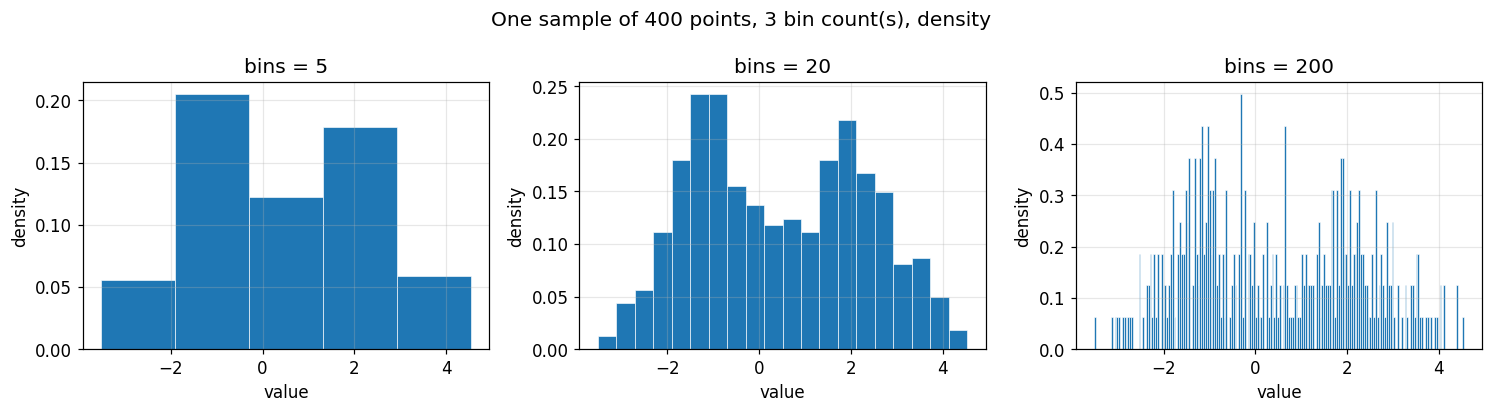

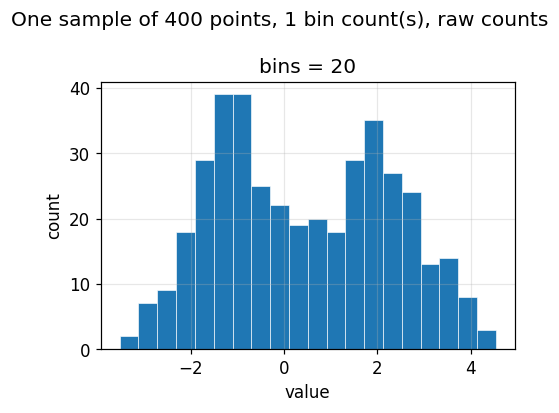

Task 10 passed.


In [25]:
# A deliberately awkward sample: two overlapping normals, 400 points.
_mixture = np.concatenate([
    np.random.default_rng(7).normal(-1.0, 1.0, 200),
    np.random.default_rng(8).normal(2.0, 1.0, 200),
])

_fig, _axes = histogram_grid(_mixture, [5, 20, 200], density=True)

assert len(_axes) == 3, f"expected three panels, got {len(_axes)}"
for _ax in _axes:
    assert _ax.get_xlabel(), "a panel has no x label"
    assert _ax.get_ylabel() == "density", \
        f"with density=True the y axis is a density, not a {_ax.get_ylabel()!r}"
    assert _ax.get_title(), "a panel has no title"
    assert len(_ax.patches) > 0, "a panel has no bars"

_fig_count, _axes_count = histogram_grid(_mixture, [20], density=False)
assert _axes_count[0].get_ylabel() == "count"

plt.show()
print("Task 10 passed.")

### Question 5 — bin count and density

Look at the three panels you just produced from `_mixture`, which was built
from **two** normal components centred at -1 and +2.

**(a)** At which bin count is the two-component structure visible? At which
is it hidden? At 200 bins, are the peaks you see real?

**(b)** Re-run `histogram_grid(_mixture, [5, 20, 200], density=False)` and
compare the y axes with the `density=True` version. The shapes are
identical but the numbers are not. Explain what `density=True` divides by,
and why that makes two samples **of different sizes** comparable on one
axis where raw counts would not be.

**(c)** A colleague shows you a histogram with a clear double peak and
concludes the population has two subgroups. What is the first question you
ask them?

bins =   5: bin width 1.611, mean points per bin  80.0, empty bins   0, tallest bar 132
            bin centres: [-2.71 -1.1   0.51  2.12  3.73]
            counts     : [ 36 132  79 115  38]
bins =  20: bin width 0.403, mean points per bin  20.0, empty bins   0, tallest bar  39
            bin centres: [-3.32 -2.91 -2.51 -2.11 -1.7  -1.3  -0.9  -0.5  -0.09  0.31  0.71  1.11
  1.52  1.92  2.32  2.73  3.13  3.53  3.93  4.34]
            counts     : [ 2  7  9 18 29 39 39 25 22 19 20 18 29 35 27 24 13 14  8  3]
bins = 200: bin width 0.040, mean points per bin   2.0, empty bins  42, tallest bar   8

same 5-bin width, edges shifted by half a bin:
            bin centres: [-3.52 -1.91 -0.29  1.32  2.93  4.54]
            counts     : [  9  95 105 102  78  11]
200-bin histogram has 49 local maxima


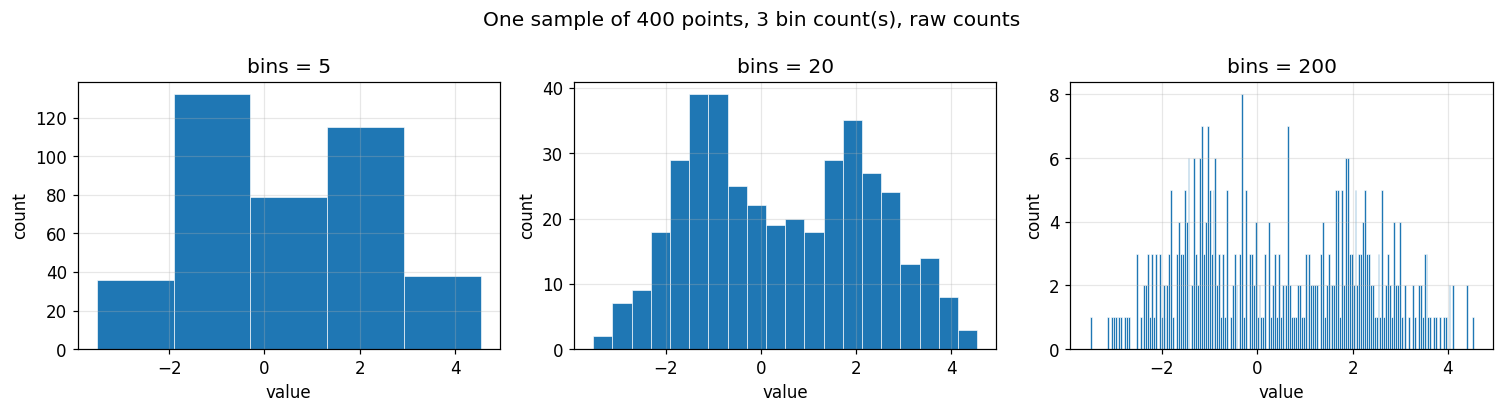

bins =   5: tallest count 132 -> density 0.2048 = 132 / (400 x 1.6110);  area under the density histogram 1.0000
bins =  20: tallest count  39 -> density 0.2421 = 39 / (400 x 0.4027);  area under the density histogram 1.0000
bins = 200: tallest count   8 -> density 0.4966 = 8 / (400 x 0.0403);  area under the density histogram 1.0000


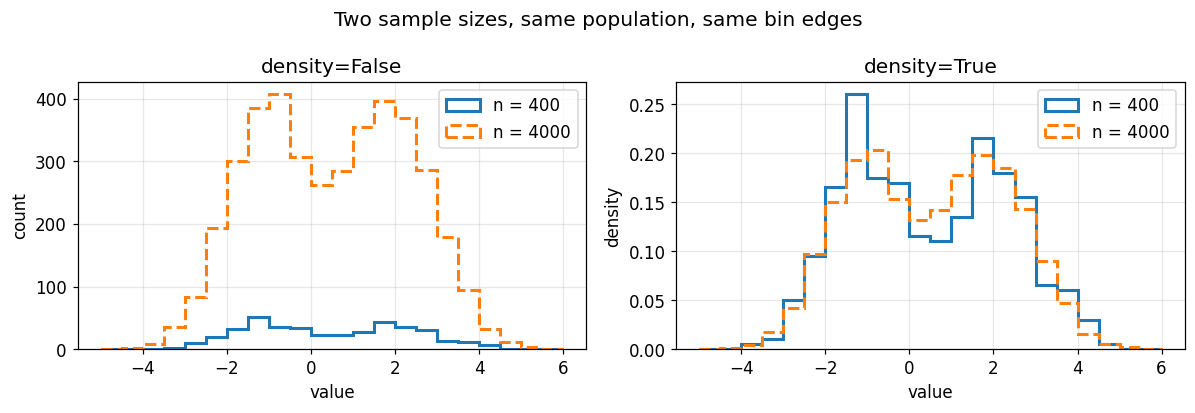

In [26]:
# (a) what each bin count actually shows
for _bins in (5, 20, 200):
    _counts, _edges = np.histogram(_mixture, bins=_bins)
    _width = _edges[1] - _edges[0]
    print(f"bins = {_bins:3}: bin width {_width:.3f}, mean points per bin {_counts.mean():5.1f}, "
          f"empty bins {(_counts == 0).sum():3}, tallest bar {_counts.max():3}")
    if _bins in (5, 20):
        print("            bin centres:", ((_edges[:-1] + _edges[1:]) / 2).round(2))
        print("            counts     :", _counts)

# The 5-bin picture depends on where the edges happen to fall:
# keep the same width and shift every edge by half a bin.
_c5, _e5 = np.histogram(_mixture, bins=5)
_w5 = _e5[1] - _e5[0]
_shifted = np.arange(_e5[0] - _w5 / 2, _e5[-1] + _w5, _w5)
_c5s, _ = np.histogram(_mixture, bins=_shifted)
print("\nsame 5-bin width, edges shifted by half a bin:")
print("            bin centres:", ((_shifted[:-1] + _shifted[1:]) / 2).round(2))
print("            counts     :", _c5s)
_c200, _ = np.histogram(_mixture, bins=200)
_peaks200 = sum(1 for i in range(1, 199) if _c200[i] > _c200[i - 1] and _c200[i] > _c200[i + 1])
print("200-bin histogram has", _peaks200, "local maxima")

# (b) the same three panels as raw counts
_fig_c, _axes_c = histogram_grid(_mixture, [5, 20, 200], density=False)
plt.show()

for _bins in (5, 20, 200):
    _counts, _edges = np.histogram(_mixture, bins=_bins)
    _dens, _ = np.histogram(_mixture, bins=_bins, density=True)
    _width = _edges[1] - _edges[0]
    print(f"bins = {_bins:3}: tallest count {_counts.max():3} -> density {_dens.max():.4f} "
          f"= {_counts.max()} / ({_mixture.size} x {_width:.4f});  "
          f"area under the density histogram {np.sum(_dens * _width):.4f}")

# Two samples of different sizes from the same mixture
_big_mixture = np.concatenate([np.random.default_rng(17).normal(-1.0, 1.0, 2000),
                               np.random.default_rng(18).normal(2.0, 1.0, 2000)])
_shared_edges = np.linspace(-5, 6, 23)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, dens in zip(axes, (False, True)):
    ax.hist(_mixture, bins=_shared_edges, density=dens, histtype="step", linewidth=2, label="n = 400")
    ax.hist(_big_mixture, bins=_shared_edges, density=dens, histtype="step", linewidth=2,
            linestyle="--", label="n = 4000")
    ax.set_xlabel("value")
    ax.set_ylabel("density" if dens else "count")
    ax.set_title("density=True" if dens else "density=False")
    ax.legend()
fig.suptitle("Two sample sizes, same population, same bin edges")
fig.tight_layout()
plt.show()

**Your answer:**

**(a)** Двокомпонентна структура чітко видна при **20 бінах** (ширина біна 0,40). Ліва вершина припадає на біни з центрами −1,30 і −0,90 (по 39 точок), права на 1,92 (35 точок), між ними западина на 0,31–1,11 (18–20 точок). Положення вершин добре відповідає центрам компонент −1 і +2. При **5 бінах** (ширина 1,61) лічильники [36, 132, 79, 115, 38] формально мають западину, але вона тримається на одному стовпчику і залежить від того, куди випали межі бінів. Якщо зсунути всі межі на половину біна при тій самій ширині, лічильники стають [9, 95, 105, 102, 78, 11], тобто одне широке плато без жодної западини. Отже, при 5 бінах структура прихована або проявляється випадково, бо ширина біна порівнянна з відстанню між компонентами (3) і втричі перевищує їхнє стандартне відхилення (1). При **200 бінах** ширина біна 0,04, у середньому 2 точки на бін, 42 біни порожні, а гістограма має 49 локальних максимумів. Ці «піки» не реальні: при двох точках на бін висота стовпчика визначається випадковістю, і кожен такий пік є шумом підрахунку, а не властивістю сукупності.

**(b)** При `density=False` на осі y кількість точок: найвищі стовпчики 132, 39 і 8. При `density=True` ті самі стовпчики мають висоти 0,2048; 0,2421; 0,4966. `density=True` ділить кількість у біні на добуток обсягу вибірки й ширини біна, наприклад 132 / (400 × 1,6110) = 0,2048, тому площа під гістограмою дорівнює одиниці (у всіх трьох випадках 1,0000) і висота стає оцінкою щільності ймовірності. Через ділення на n дві вибірки різного обсягу стають порівнянними на одній осі. На останньому рисунку вибірки з 400 і 4000 точок з тієї самої сукупності при `density=False` відрізняються вдесятеро за висотою, і менша з них майже зливається з віссю, тоді як при `density=True` обидві криві лягають одна на одну і відрізняються лише шумом малої вибірки. Ділення на ширину біна, своєю чергою, робить висоти порівнянними між гістограмами з різною кількістю бінів.

**(c)** Перше запитання: на скількох спостереженнях побудовано гістограму і чи зберігається подвійна вершина, якщо змінити кількість бінів або зсунути їхні межі? Як показав пункт (a), западина між вершинами може бути наслідком вибору бінів або шуму малої вибірки. Лише якщо вона стійка до цих змін, має сенс шукати зовнішню змінну, яка розділяє ці дві підгрупи.

## 12. Task 11 — Open-ended

No assert. This one is marked on the written analysis.

You are given a sample of 5000 measurements below, produced by a generator
whose parameters you are not told. Your task is to **characterise it and
say what you would do with the extreme values**, using only the tools from
Practice 1.

Work through at least the following, and write up what you find:

1. Describe the array: shape, dtype, how much memory it occupies.
2. Compute the mean, the median, the standard deviation, the minimum and
   the maximum. The mean and the median differ noticeably. What does that
   tell you before you have plotted anything?
3. Plot it as a histogram. Choose the bin count deliberately and justify
   your choice in one sentence.
4. Apply the k-sigma rule from Task 5 at k = 3. How many points are
   flagged? Compare that count with the roughly 0.27 % you would expect
   from a normal sample of this size.
5. Now the judgement. Recompute the mean and standard deviation **with the
   flagged points removed**. Report both versions. Then argue, in a
   paragraph, whether the flagged points should be removed — and be
   explicit about what you would need to know about *how the data was
   measured* before you could answer that with any confidence.

A good answer treats step 5 as a question about the measurement process,
not about the numbers. A weak answer deletes the outliers because a rule
said so.

In [27]:
# The data. Do not modify this cell.
_hidden_rng = np.random.default_rng(31337)
mystery_sample = np.concatenate([
    _hidden_rng.normal(10.0, 2.0, 4_900),
    _hidden_rng.uniform(25.0, 60.0, 100),
])
_hidden_rng.shuffle(mystery_sample)

print("mystery_sample is ready:", mystery_sample.shape)

mystery_sample is ready: (5000,)


In [28]:
# Step 1. Describe the array
print("shape :", mystery_sample.shape)
print("dtype :", mystery_sample.dtype)
print("ndim  :", mystery_sample.ndim, "  size:", mystery_sample.size)
print("nbytes:", mystery_sample.nbytes, "bytes =", mystery_sample.size, "x",
      mystery_sample.itemsize, "bytes per float64")
print("any NaN:", bool(np.isnan(mystery_sample).any()))

shape : (5000,)
dtype : float64
ndim  : 1   size: 5000
nbytes: 40000 bytes = 5000 x 8 bytes per float64
any NaN: False


In [29]:
# Step 2. Location and spread
_m_mean = mystery_sample.mean()
_m_median = np.median(mystery_sample)
_m_sd = mystery_sample.std()
print(f"mean   {_m_mean:8.4f}")
print(f"median {_m_median:8.4f}")
print(f"sd     {_m_sd:8.4f}   (ddof=0)")
print(f"min    {mystery_sample.min():8.4f}")
print(f"max    {mystery_sample.max():8.4f}")
print(f"mean - median = {_m_mean - _m_median:+.4f}, i.e. {(_m_mean - _m_median) / _m_sd:+.3f} sd")
print()
for q in (1, 5, 25, 50, 75, 95, 99):
    print(f"  {q:2}th percentile {np.percentile(mystery_sample, q):8.4f}")

mean    10.6311
median  10.0925
sd       5.0650   (ddof=0)
min      2.5716
max     59.7279
mean - median = +0.5386, i.e. +0.106 sd

   1th percentile   5.2027
   5th percentile   6.7222
  25th percentile   8.6538
  50th percentile  10.0925
  75th percentile  11.4790
  95th percentile  13.7219
  99th percentile  41.2580


number of bins: 58


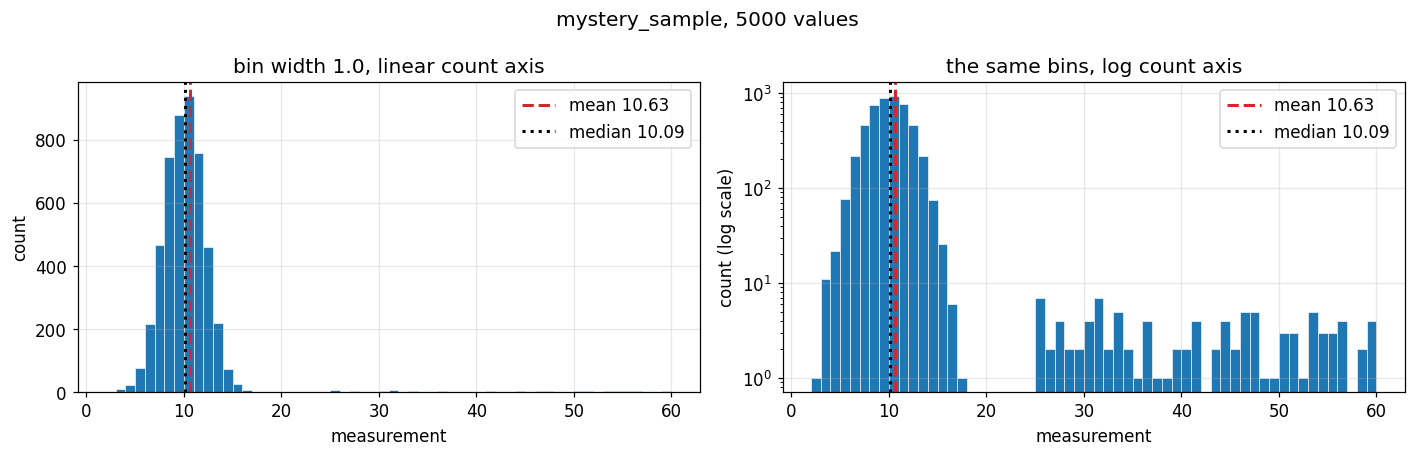

count of values in [20, 25): 0
count of values >= 25      : 100
mean count per 1-unit bin over [25, 60): 2.86


In [30]:
# Step 3. Histogram with a deliberate bin width of 1.0 unit
_edges_m = np.arange(np.floor(mystery_sample.min()), np.ceil(mystery_sample.max()) + 1.0, 1.0)
print("number of bins:", len(_edges_m) - 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(mystery_sample, bins=_edges_m, edgecolor="white", linewidth=0.4)
axes[0].set_xlabel("measurement")
axes[0].set_ylabel("count")
axes[0].set_title("bin width 1.0, linear count axis")
axes[1].hist(mystery_sample, bins=_edges_m, edgecolor="white", linewidth=0.4)
axes[1].set_yscale("log")
axes[1].set_xlabel("measurement")
axes[1].set_ylabel("count (log scale)")
axes[1].set_title("the same bins, log count axis")
for ax in axes:
    ax.axvline(_m_mean, color="tab:red", linestyle="--", label=f"mean {_m_mean:.2f}")
    ax.axvline(_m_median, color="black", linestyle=":", label=f"median {_m_median:.2f}")
    ax.legend()
fig.suptitle("mystery_sample, 5000 values")
fig.tight_layout()
plt.show()

_c_m, _ = np.histogram(mystery_sample, bins=_edges_m)
print("count of values in [20, 25):", int(((mystery_sample >= 20) & (mystery_sample < 25)).sum()))
print("count of values >= 25      :", int((mystery_sample >= 25).sum()))
print("mean count per 1-unit bin over [25, 60):", _c_m[_edges_m[:-1] >= 25].mean().round(2))

In [31]:
# Step 4. The 3-sigma rule
_m_mask, _m_out = sigma_outliers(mystery_sample, k=3.0)
_low_fence, _high_fence = _m_mean - 3 * _m_sd, _m_mean + 3 * _m_sd
print(f"fences: [{_low_fence:.4f}, {_high_fence:.4f}]")
print(f"flagged: {_m_mask.sum()} of {mystery_sample.size} = {100 * _m_mask.mean():.2f} %")
print(f"expected for a normal sample of this size: about {0.0027 * mystery_sample.size:.1f} points")
print(f"flagged below the lower fence: {(mystery_sample < _low_fence).sum()}, "
      f"above the upper fence: {(mystery_sample > _high_fence).sum()}")
print(f"flagged values range from {_m_out.min():.3f} to {_m_out.max():.3f}")
print(f"unflagged values above 20: {((mystery_sample > 20) & ~_m_mask).sum()}")

fences: [-4.5641, 25.8262]
flagged: 94 of 5000 = 1.88 %
expected for a normal sample of this size: about 13.5 points
flagged below the lower fence: 0, above the upper fence: 94
flagged values range from 25.925 to 59.728
unflagged values above 20: 6


In [32]:
# Step 5. Both versions of the summary
_kept = mystery_sample[~_m_mask]
print(f"{'':22} {'n':>6} {'mean':>9} {'median':>9} {'sd (ddof=1)':>12}")
print(f"{'all points':22} {mystery_sample.size:>6} {mystery_sample.mean():>9.4f} "
      f"{np.median(mystery_sample):>9.4f} {mystery_sample.std(ddof=1):>12.4f}")
print(f"{'flagged points removed':22} {_kept.size:>6} {_kept.mean():>9.4f} "
      f"{np.median(_kept):>9.4f} {_kept.std(ddof=1):>12.4f}")

# Is what remains consistent with one normal? Re-apply the same rule once more.
_mask2, _ = sigma_outliers(_kept, k=3.0)
print(f"\nre-applying the 3-sigma rule to the remaining {_kept.size} points flags {_mask2.sum()} more "
      f"({100 * _mask2.mean():.2f} %, normal expectation 0.27 %)")
print(f"share of the remaining points within 1 / 2 sd of their mean: "
      f"{np.mean(np.abs(_kept - _kept.mean()) < _kept.std()):.4f} / "
      f"{np.mean(np.abs(_kept - _kept.mean()) < 2 * _kept.std()):.4f}  (normal: 0.6827 / 0.9545)")

                            n      mean    median  sd (ddof=1)
all points               5000   10.6311   10.0925       5.0655
flagged points removed   4906   10.0210   10.0419       2.0932

re-applying the 3-sigma rule to the remaining 4906 points flags 15 more (0.31 %, normal expectation 0.27 %)
share of the remaining points within 1 / 2 sd of their mean: 0.7006 / 0.9651  (normal: 0.6827 / 0.9545)


**Your write-up:**

**Опис масиву.** `mystery_sample` є одновимірним масивом форми `(5000,)` з типом `float64`, займає 40 000 байт (5000 значень по 8 байт) і не містить пропусків.

**Положення і розкид.** Середнє 10,6311, медіана 10,0925, стандартне відхилення 5,0650, мінімум 2,5716, максимум 59,7279. Середнє перевищує медіану на 0,54 (0,11 sd), і це ще до побудови графіка вказує на правосторонню асиметрію: невелика кількість великих значень тягне середнє вгору, а медіана до них нечутлива. Процентилі підтверджують це. Міжквартильний розмах 8,65–11,48 (IQR = 2,83) відповідає для нормального розподілу стандартному відхиленню близько 2,1, що в 2,4 раза менше за обчислене 5,07. При цьому 95-й процентиль дорівнює 13,72, а 99-й одразу 41,26. Такий стрибок означає, що верхні близько 2 % значень утворюють окрему групу, а не продовжують основний розподіл.

**Гістограма.** Я обрав ширину біна 1,0 (58 бінів), бо це половина розкиду основної маси, тож дзвін отримує близько п'ятнадцяти стовпчиків, а розріджена область 25–60 ще збирає в середньому 2,86 значення на бін. Другу панель побудовано з логарифмічною віссю лічильників, щоб побачити рідкісні значення. Картина однозначна: симетричний дзвін навколо 10 приблизно від 3 до 18, далі порожній проміжок (у [20, 25) немає жодного значення), а потім рівне плато від 25 до 60, яке містить рівно 100 значень. Плато не спадає з віддаленням від центру, як мав би спадати хвіст нормального розподілу, тому ці значення найімовірніше породжені іншим процесом.

**Правило 3σ.** Межі дорівнюють [−4,56; 25,83], позначено 94 значення (1,88 %), усі над верхньою межею, у діапазоні 25,93–59,73. Для нормальної вибірки такого обсягу очікувалося б близько 13,5 точок, тобто позначено майже в сім разів більше, ніж дає випадковість. Показово й те, чого правило не помітило. Шість значень плато між 25 і 25,83 лишилися непозначеними, бо межу обчислено з середнього й стандартного відхилення, які саме ці викиди й роздули (sd 5,07 замість приблизно 2). Викиди розширюють критерій, що мав би їх зловити. З тієї ж причини нижня межа −4,56 лежить далеко за мінімумом 2,57, і жодне значення лівого хвоста не позначено.

**Дві версії підсумків.** З усіма точками: n = 5000, середнє 10,6311, медіана 10,0925, sd (ddof = 1) 5,0655. Без позначених точок: n = 4906, середнє 10,0210, медіана 10,0419, sd 2,0932. Медіана майже не змінилася (на 0,05), середнє зменшилося на 0,61, а стандартне відхилення у 2,4 раза. Повторне застосування правила до решти позначає ще 15 точок (0,31 % при нормальному очікуванні 0,27 %), тож без плато дані узгоджуються з одним нормальним розподілом із середнім близько 10 і sd близько 2, якщо не зважати на шість залишених значень біля 25.

**Чи видаляти.** Правило знайшло реальну особливість даних, проте відповісти, чи це помилки, числа не можуть. Відповідь залежить від того, як отримано вимірювання. Спершу потрібно знати, яку величину і в яких одиницях вимірювали та чи фізично можливі для неї значення 25–60. Далі важливо, чи має прилад робочий діапазон, за межами якого він видає насичення або службові коди, і чи не пов'язані великі значення з певним приладом, оператором, партією або часовим проміжком (зміна одиниць, збій калібрування). Варто перевірити, чи відтворюються ці значення при повторному вимірюванні тих самих об'єктів, і нарешті, яка мета аналізу: типовий рівень процесу чи саме частота рідкісних великих значень. Рівномірне плато, відокремлене від дзвона порожнім проміжком, більше схоже на окремий механізм (несправність, інша підгрупа об'єктів, інший прилад), ніж на хвіст того самого розподілу. Якщо документація підтвердить технічну природу цих значень, їх слід вилучити й описати в звіті, причому межею природніше взяти порожній проміжок 18–25 (усі 100 значень ≥ 25), а не межу 3σ, яка відсікла лише 94. Якщо ж це справжні рідкісні події, їх видалення знищить найцікавішу частину даних, і тоді правильно описувати вибірку як суміш двох груп. Поки цих відомостей немає, я не видаляв би точки мовчки: звітував би про основну групу (медіана 10,04, sd 2,09), окремо повідомляв би, що близько 2 % вимірювань лежать у діапазоні 25–60 і потребують перевірки, а для центральної тенденції використовував би медіану, яку ця група майже не зсуває.

## 13. Before you submit

- Runtime → **Restart and run all**. Every cell must execute in order with
  no error and every assert must pass.
- Every written question has an answer that refers to numbers you actually
  produced.
- Task 11 has a written conclusion, not only code.